# CSI Fall Detection - 3 Class Temporal LSTM Model

Classes:
- 0 = Falling
- 1 = Empty
- 2 = Small Activity

Assumptions:
- 200 ms per record
- WINDOW_SIZE = 15 records (~3 seconds)
- Non-overlapping windows
- Drop remainder records


In [10]:
!pip install -q keras-tuner


[notice] A new release of pip is available: 25.1.1 -> 26.1.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [11]:
import os
import glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout, BatchNormalization
from tensorflow.keras.callbacks import EarlyStopping


In [12]:
# from google.colab import drive
# drive.mount('/content/drive')


In [13]:
DATA_DIR = "d:/WIFI-HAR/dataset"
WINDOW_SIZE = 15

def process_csi_string(csi_str):

    clean_str = csi_str.replace('[','').replace(']','').strip()
    clean_str = ' '.join(clean_str.split())

    csi_data = np.fromstring(clean_str, sep=' ', dtype=int)

    if len(csi_data) < 10:
        return None

    if len(csi_data) % 2 != 0:
        csi_data = csi_data[:-1]

    imag = csi_data[0::2]
    real = csi_data[1::2]

    amplitude = np.sqrt(imag**2 + real**2)

    target_len = 128

    if len(amplitude) < target_len:
        temp = np.zeros(target_len)
        temp[:len(amplitude)] = amplitude
        amplitude = temp
    elif len(amplitude) > target_len:
        amplitude = amplitude[:target_len]

    return amplitude


In [14]:
X = []
y = []

all_files = glob.glob(os.path.join(DATA_DIR, "*.csv"))

for file_path in all_files:

    filename = os.path.basename(file_path)

    try:
        df = pd.read_csv(
            file_path,
            encoding='utf-16',
            engine='python',
            on_bad_lines='skip'
        )
    except Exception as e:
        print(filename, e)
        continue

    if 'CSI_DATA' not in df.columns:
        continue

    if "falling_" in filename:
        label = 0
    elif "empty_" in filename:
        label = 1
    elif "small_activity_" in filename:
        label = 2
    else:
        continue

    packets = []

    for _, row in df.iterrows():

        csi_str = str(row['CSI_DATA'])

        if csi_str == 'nan' or not csi_str:
            continue

        amp = process_csi_string(csi_str)

        if amp is None:
            continue

        packets.append(amp)

    for start in range(0, len(packets) - WINDOW_SIZE + 1, 5):

        window = packets[start:start+WINDOW_SIZE]

        if len(window) == WINDOW_SIZE:
            X.append(window)
            y.append(label)

X = np.array(X)
y = np.array(y)

print("X shape:", X.shape)
print("y shape:", y.shape)
print(np.unique(y, return_counts=True))


X shape: (627, 15, 128)
y shape: (627,)
(array([0, 1, 2]), array([ 47, 445, 135]))


## Exploratory Data Analysis (EDA)
Visualizing class distributions and the temporal CSI amplitude signatures (Heatmaps) for each class.

C:\Users\ASUS\AppData\Local\Temp\ipykernel_33760\2200001058.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=y, palette='viridis')


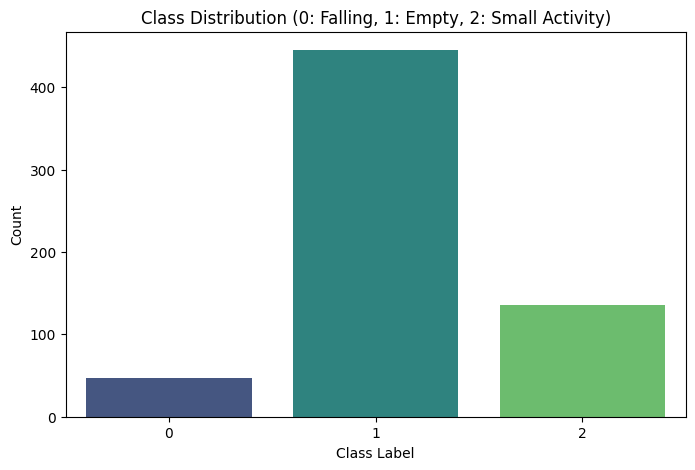

In [15]:
plt.figure(figsize=(8, 5))
sns.countplot(x=y, palette='viridis')
plt.title('Class Distribution (0: Falling, 1: Empty, 2: Small Activity)')
plt.xlabel('Class Label')
plt.ylabel('Count')
plt.show()


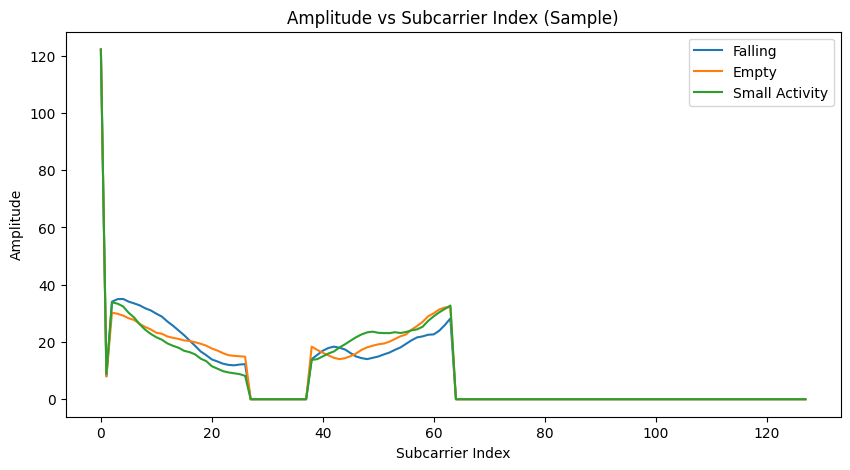

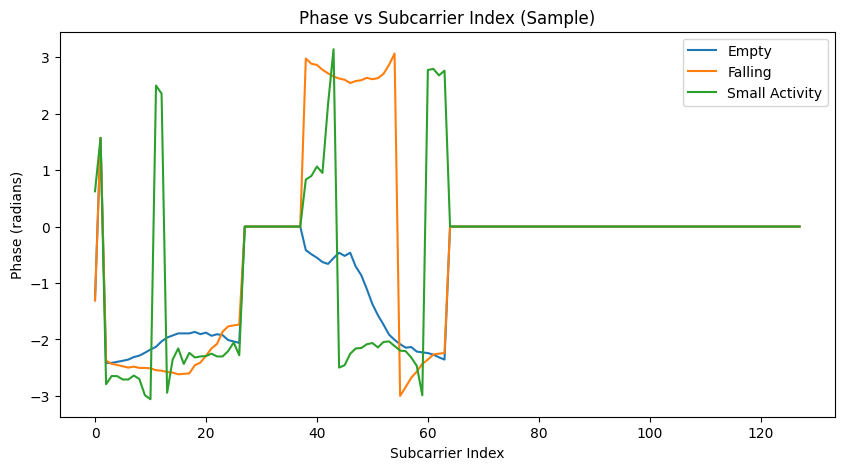

In [16]:
import pandas as pd
import numpy as np
import os, glob
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
class_names = {0: "Falling", 1: "Empty", 2: "Small Activity"}
# 1. Amplitude and Subcarrier index for all classes
plt.figure(figsize=(10, 5))
for class_label in [0, 1, 2]:
    idx = np.where(y == class_label)[0]
    if len(idx) > 0:
        # Take the mean amplitude across the window for the first sample
        sample_amp = np.mean(X[idx[0]], axis=0)
        plt.plot(sample_amp, label=class_names[class_label])
plt.title('Amplitude vs Subcarrier Index (Sample)')
plt.xlabel('Subcarrier Index')
plt.ylabel('Amplitude')
plt.legend()
plt.show()

# 2. Phase and Subcarrier index for all classes
def extract_phase(csi_str):
    clean_str = csi_str.replace('[','').replace(']','').strip()
    clean_str = ' '.join(clean_str.split())
    csi_data = np.fromstring(clean_str, sep=' ', dtype=int)
    if len(csi_data) < 10: return None
    if len(csi_data) % 2 != 0: csi_data = csi_data[:-1]
    imag = csi_data[0::2]
    real = csi_data[1::2]
    phase = np.arctan2(imag, real)
    target_len = 128
    if len(phase) < target_len:
        temp = np.zeros(target_len)
        temp[:len(phase)] = phase
        phase = temp
    elif len(phase) > target_len:
        phase = phase[:target_len]
    return phase

# Re-read one raw CSV per class to get phase
plt.figure(figsize=(10, 5))
found_classes = set()
all_files = glob.glob(os.path.join(DATA_DIR, "*.csv"))
for file_path in all_files:
    filename = os.path.basename(file_path)
    label = -1
    if "falling_" in filename: label = 0
    elif "empty_" in filename: label = 1
    elif "small_activity_" in filename: label = 2
    
    if label != -1 and label not in found_classes:
        try:
            df = pd.read_csv(file_path, encoding='utf-16', engine='python', on_bad_lines='skip')
            if 'CSI_DATA' in df.columns:
                for _, row in df.iterrows():
                    csi_str = str(row['CSI_DATA'])
                    if csi_str != 'nan' and csi_str:
                        phase = extract_phase(csi_str)
                        if phase is not None:
                            plt.plot(phase, label=class_names[label])
                            found_classes.add(label)
                            break
        except: pass
    if len(found_classes) == 3: break

plt.title('Phase vs Subcarrier Index (Sample)')
plt.xlabel('Subcarrier Index')
plt.ylabel('Phase (radians)')
plt.legend()
plt.show()


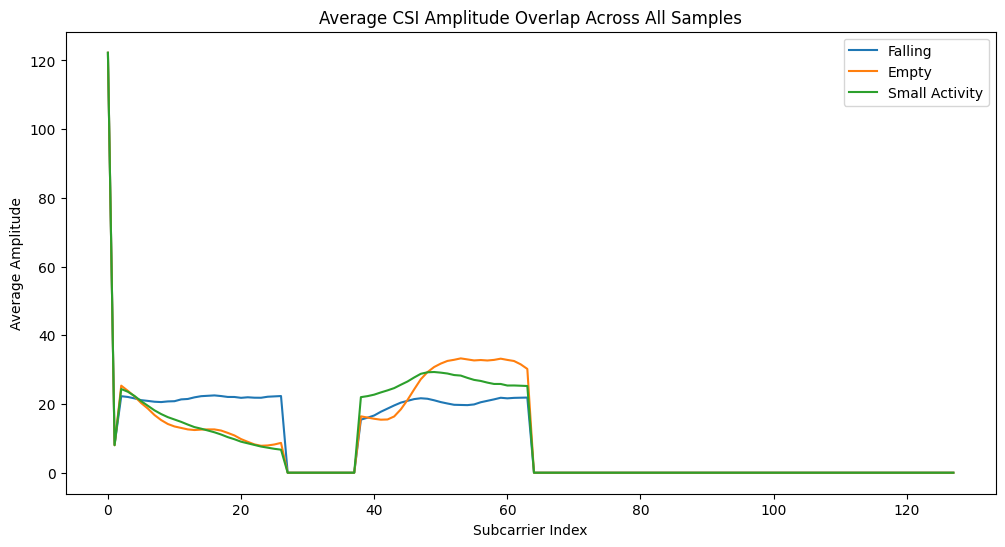

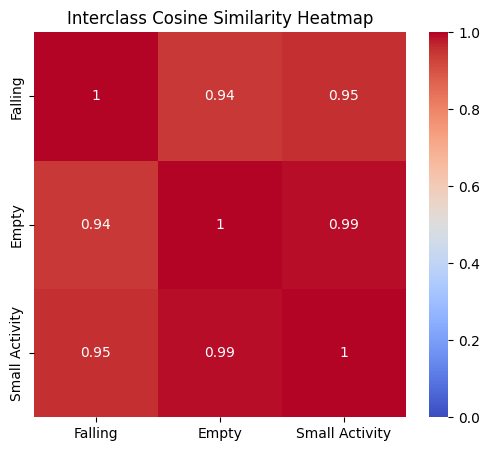

In [17]:
# 3. Average CSI Amplitude overlap graph
plt.figure(figsize=(12, 6))
avg_amps = []
labels_for_sim = []

for class_label in [0, 1, 2]:
    idx = np.where(y == class_label)[0]
    if len(idx) > 0:
        # X shape is (samples, 15, 128). Average over all samples and all time steps.
        class_avg = np.mean(X[idx], axis=(0, 1))
        avg_amps.append(class_avg)
        labels_for_sim.append(class_names[class_label])
        
        plt.plot(class_avg, label=class_names[class_label])

plt.title('Average CSI Amplitude Overlap Across All Samples')
plt.xlabel('Subcarrier Index')
plt.ylabel('Average Amplitude')
plt.legend()
plt.show()

# 4. Interclass cosine similarity heatmap
if len(avg_amps) > 1:
    sim_matrix = cosine_similarity(avg_amps)
    plt.figure(figsize=(6, 5))
    import seaborn as sns
    sns.heatmap(sim_matrix, annot=True, xticklabels=labels_for_sim, yticklabels=labels_for_sim, cmap='coolwarm', vmin=0, vmax=1)
    plt.title('Interclass Cosine Similarity Heatmap')
    plt.show()


In [18]:
samples, timesteps, features = X.shape

X_flat = X.reshape(-1, features)

scaler = StandardScaler()
X_flat = scaler.fit_transform(X_flat)

X = X_flat.reshape(samples, timesteps, features)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(X_train.shape)
print(X_test.shape)


(501, 15, 128)
(126, 15, 128)


In [19]:
model = Sequential([

    LSTM(64, return_sequences=True, input_shape=(WINDOW_SIZE,128)),
    BatchNormalization(),

    LSTM(64),
    BatchNormalization(),

    Dense(128, activation='relu'),
    Dropout(0.5),

    Dense(3, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()


c:\Users\ASUS\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 15, 64)         │        49,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 15, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │         8,320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 91,651 (358.01 KB)

 Trainable params: 91,395 (357.01 KB)

 Non-trainable params: 256 (1.00 KB)

In [20]:
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stop]
)


Epoch 1/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 43ms/step - accuracy: 0.7125 - loss: 0.6607 - val_accuracy: 0.9307 - val_loss: 0.7340
Epoch 2/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9475 - loss: 0.1707 - val_accuracy: 0.9505 - val_loss: 0.5542
Epoch 3/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.9775 - loss: 0.0972 - val_accuracy: 0.9604 - val_loss: 0.4353
Epoch 4/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9900 - loss: 0.0518 - val_accuracy: 0.9604 - val_loss: 0.3587
Epoch 5/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9900 - loss: 0.0420 - val_accuracy: 0.9604 - val_loss: 0.2863
Epoch 6/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9950 - loss: 0.0237 - val_accuracy: 0.9604 - val_loss: 0.2515
Epoch 7/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9975 - loss: 0.0203 - val_accuracy: 0.9604 - val_loss: 0.2035
Epoch 8/30
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9950 - loss: 0.0337 - val_accuracy: 0.9505 - v

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step
Accuracy: 0.9841269841269841
                precision    recall  f1-score   support

       Falling       1.00      1.00      1.00        10
         Empty       0.98      1.00      0.99        89
Small Activity       1.00      0.93      0.96        27

      accuracy                           0.98       126
     macro avg       0.99      0.98      0.98       126
  weighted avg       0.98      0.98      0.98       126



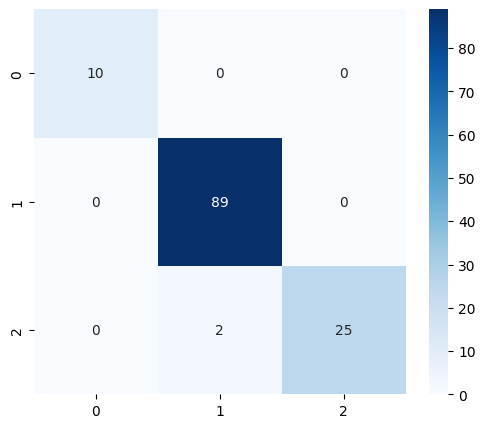

In [21]:
pred = model.predict(X_test)
y_pred = np.argmax(pred, axis=1)

print("Accuracy:", accuracy_score(y_test, y_pred))

print(classification_report(
    y_test,
    y_pred,
    target_names=["Falling","Empty","Small Activity"]
))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.show()


In [23]:
model.save("fall_detection_3class_lstm.h5")

converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
converter.target_spec.supported_ops = [tf.lite.OpsSet.TFLITE_BUILTINS, tf.lite.OpsSet.SELECT_TF_OPS]
converter._experimental_lower_tensor_list_ops = False

tflite_model = converter.convert()

with open("fall_detection_3class_lstm.tflite","wb") as f:
    f.write(tflite_model)

print("Saved LSTM H5 and TFLite models")


INFO:tensorflow:Assets written to: C:\Users\ASUS\AppData\Local\Temp\tmp9cxmq_x_\assets


INFO:tensorflow:Assets written to: C:\Users\ASUS\AppData\Local\Temp\tmp9cxmq_x_\assets


Saved artifact at 'C:\Users\ASUS\AppData\Local\Temp\tmp9cxmq_x_'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 15, 128), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 3), dtype=tf.float32, name=None)
Captures:
  1912409760464: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1912349439760: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1912409761040: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1912408834896: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1912408836048: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1912349428432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1912408836624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1912408293456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1912408307664: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1912408835472: TensorSpec(shape=(), dtype=tf.resource, name=None)
  1912408842

In [24]:
import numpy as np
from sklearn.metrics import confusion_matrix

# Assuming y_test and y_pred are already available from your previous evaluation cell
cm = confusion_matrix(y_test, y_pred)
class_names = {0: "Falling", 1: "Empty", 2: "Small Activity"}

print("="*50)
print("CLASS-WISE TP, TN, FP, FN")
print("="*50)

# Calculate metrics for each class
for i in range(3):
    # True Positives: The diagonal element for this class
    tp = cm[i, i]
    
    # False Positives: Sum of the predicted column for this class, minus TP
    fp = np.sum(cm[:, i]) - tp
    
    # False Negatives: Sum of the true row for this class, minus TP
    fn = np.sum(cm[i, :]) - tp
    
    # True Negatives: Sum of all elements in the matrix minus (TP + FP + FN)
    tn = np.sum(cm) - (tp + fp + fn)
    
    class_name = class_names.get(i, f"Class {i}")
    
    print(f"Metrics for: {class_name}")
    print(f"  True Positives  (TP) : {tp}  -> (Correctly identified as {class_name})")
    print(f"  True Negatives  (TN) : {tn}  -> (Correctly identified as NOT {class_name})")
    print(f"  False Positives (FP) : {fp}  -> (Incorrectly flagged as {class_name})")
    print(f"  False Negatives (FN) : {fn}  -> (Missed {class_name} events)")
    print("-" * 50)


CLASS-WISE TP, TN, FP, FN
Metrics for: Falling
  True Positives  (TP) : 10  -> (Correctly identified as Falling)
  True Negatives  (TN) : 116  -> (Correctly identified as NOT Falling)
  False Positives (FP) : 0  -> (Incorrectly flagged as Falling)
  False Negatives (FN) : 0  -> (Missed Falling events)
--------------------------------------------------
Metrics for: Empty
  True Positives  (TP) : 89  -> (Correctly identified as Empty)
  True Negatives  (TN) : 35  -> (Correctly identified as NOT Empty)
  False Positives (FP) : 2  -> (Incorrectly flagged as Empty)
  False Negatives (FN) : 0  -> (Missed Empty events)
--------------------------------------------------
Metrics for: Small Activity
  True Positives  (TP) : 25  -> (Correctly identified as Small Activity)
  True Negatives  (TN) : 99  -> (Correctly identified as NOT Small Activity)
  False Positives (FP) : 0  -> (Incorrectly flagged as Small Activity)
  False Negatives (FN) : 2  -> (Missed Small Activity events)
------------------

In [25]:
import numpy as np

# 1. Generate random dummy data matching the input shape of the model
# The shape must be (batch_size, time_steps, features)
# In this case: (1, WINDOW_SIZE, 128)
dummy_input = np.random.randn(1, WINDOW_SIZE, 128)

# Note: If you used StandardScaler during training, in a real scenario you would scale 
# the new data first. But for a random dummy test, we can just pass it directly.

probabilities = model.predict(dummy_input, verbose=0)[0]

# 3. Extract the predicted class and confidence
predicted_class_idx = np.argmax(probabilities)
confidence = probabilities[predicted_class_idx] * 100

# Map index to class name
class_names = {0: "Falling", 1: "Empty", 2: "Small Activity"}
predicted_class_name = class_names[predicted_class_idx]

# 4. Print the results
print("="*50)
print("RANDOM INFERENCE TEST RESULTS")
print("="*50)
print(f"Predicted Class : {predicted_class_name} (Class {predicted_class_idx})")
print(f"Confidence      : {confidence:.2f}%")
print("-" * 50)
print("Raw Softmax Probabilities:")
print(f"  - Falling (0)        : {probabilities[0]*100:.2f}%")
print(f"  - Empty (1)          : {probabilities[1]*100:.2f}%")
print(f"  - Small Activity (2) : {probabilities[2]*100:.2f}%")
print("="*50)


RANDOM INFERENCE TEST RESULTS
Predicted Class : Empty (Class 1)
Confidence      : 42.52%
--------------------------------------------------
Raw Softmax Probabilities:
  - Falling (0)        : 28.80%
  - Empty (1)          : 42.52%
  - Small Activity (2) : 28.69%
